# Lab 9: Visualizing SSH Data in a Movie

In this notebook, we'll see how to create movies from data. A movie is just a set of frames that we view in quick succession and they can be effective tools for examining data and sharing it with our colleagues. To make a movie in Python, we can generate a series of plots and then stitch them together into a movie format. In this tutorial, we will generate a series of plots using the `cartopy` module and then use the `moviepy` module to format them together into a movie.

This notebook has three parts:
1. Download sea surface height data using Copernicus' `copernicusmarine` package
2. Generate panels for sea surface height in the Pacific Ocean
3. Stitch together them to show variability in sea surface height over the year 2026
4. Test a few additional updates to the movie formatting and interpretation

**Import the modules for this notebook**

In [1]:
# import the data and plotting modules from previous labs
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Rectangle
import netCDF4 as nc4
from datetime import datetime, date
import copernicusmarine
import cartopy
import cartopy.crs as ccrs

# import the moviepy module
import moviepy.video.io.ImageSequenceClip

## Part 1: Downloading Sea Surface Height Data via the Copernicus Marine Service

In this lab, we will use gridded sea level anomaly (SLA) data in the [Global Ocean Gridded L4 Sea Surface Heights And Derived Variables Nrt](https://data.marine.copernicus.eu/product/SEALEVEL_GLO_PHY_L4_NRT_008_046/files?path=SEALEVEL_GLO_PHY_L4_NRT_008_046%2Fcmems_obs-sl_glo_phy-ssh_nrt_allsat-l4-duacs-0.125deg_P1D_202506%2F2026%2F10%2F&subdataset=cmems_obs-sl_glo_phy-ssh_nrt_allsat-l4-duacs-0.125deg_P1D_202506). The steps to obtain this data are similar to those introduced in the previous lab for interfacing with Earthdata.

As before, start by defining a folder where the data will be downloaded:

In [2]:
# directory where the files will be stored
data_folder = '../data/labs/lab09/data'

Next, let's "log in" to the Copernicus Marine service:

In [3]:
# log in to the Copernicus Marine service
copernicusmarine.login();

INFO - 2026-10-25T23:54:11Z - Using existing credentials from /Users/mike/.copernicusmarine/.copernicusmarine-credentials. Use --force-overwrite combined with credentials (specified by arguments, netrc file or environment variables) to always overwrite.


Up next, we'll provide a query to determine which files exist. Here, let's gather all of the sea surface height anomaly files for the year 2026. The query using the `copernicusmarine` module takes a dictionary in the following form:

In [4]:
# generate a dictionary for the query
get_options = {
    "dataset_id": 'cmems_obs-sl_glo_phy-ssh_nrt_allsat-l4-duacs-0.125deg_P1D',
    "output_directory": data_folder,
    "dataset_version": "202506",
    "sync": True
    }

Next, we can take a peek at the list of files found using a "dry run" for a preview:

In [5]:
# examine a preview
preview = copernicusmarine.get(**get_options, dry_run=True)

# print some stats
print(f"Files selected: {len(preview.files)}")
print(f"Total size: {preview.total_size}")

INFO - 2026-10-25T23:54:14Z - Selected dataset version: "202506"
INFO - 2026-10-25T23:54:14Z - Selected dataset part: "default"
INFO - 2026-10-25T23:54:15Z - Listing files on remote server...
1it [00:01,  1.52s/it]
INFO - 2026-10-25T23:54:16Z - Total size of the download: 29.37 GB.


Files selected: 847
Total size: 30070.76630973816


Using our query, we'll download the data using the download command:

In [6]:
# Download files - uncomment to run
# result = copernicusmarine.get(**get_options)

## Part 2: Generating Movie Panels

To make a movie, we will need to make the panels first and then stitch them together.
### Make a function to read and plot the data
To generate a plot for all of our data, we would like to loop through each data file and generate an identical plot. To facilitate this process, first we will write a function that will generate a plot for us.

In [7]:
# create a function called create_panel that takes in the following arguments:
#       - input_file: a path to an input file (nc)
#       - output_file: a path to an output file (png)
def create_panel(input_file, output_file, save_as_image=True):

    # open the input_file and read the lon, lat, and data
    ds = nc4.Dataset(input_file)
    lon = np.copy(ds.variables['longitude'])
    lat = np.copy(ds.variables['latitude'])
    SLA = np.copy(ds.variables['sla'][:,:,:][0,:,:])
    ds.close()

    # make the figure
    fig = plt.figure(figsize=(9,7))
    ax = plt.axes(projection=ccrs.Orthographic(central_longitude=-150))
    C = plt.pcolormesh(lon, lat, SLA,
                       transform=ccrs.PlateCarree(), vmin=-1, vmax=1, cmap='RdYlBu_r')
    cbar = plt.colorbar(C, shrink=0.65, aspect=20*0.65)
    cbar.set_label('Sea Surface Height Anomaly (m)')
    ax.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
    
    # make a title with the figure date
    year = input_file.split('_')[-2][:4]
    month = input_file.split('_')[-2][4:6]
    day = input_file.split('_')[-2][6:8]
    plt.title(year+'/'+month+'/'+day)

    if save_as_image:
        # save the figure to the output_file
        plt.savefig(output_file)#, bbox_inches='tight')
    
        # close the figure
        plt.close(fig)
    else:
        plt.show()

### Test one file
Test the function above for just one file. Once you're happy with the output, then we can loop through all of the available data files to generate the contents of our movie.

In [8]:
# define a directory for this lab
lab_directory = '../data/labs/lab09'

# make a folder for ssha_panel08s
if 'ssha_panels' not in os.listdir(lab_directory):
    os.mkdir(os.path.join(lab_directory, 'ssha_panels'))

output_dir = os.path.join(lab_directory, 'ssha_panels')

Then, test the panel function:

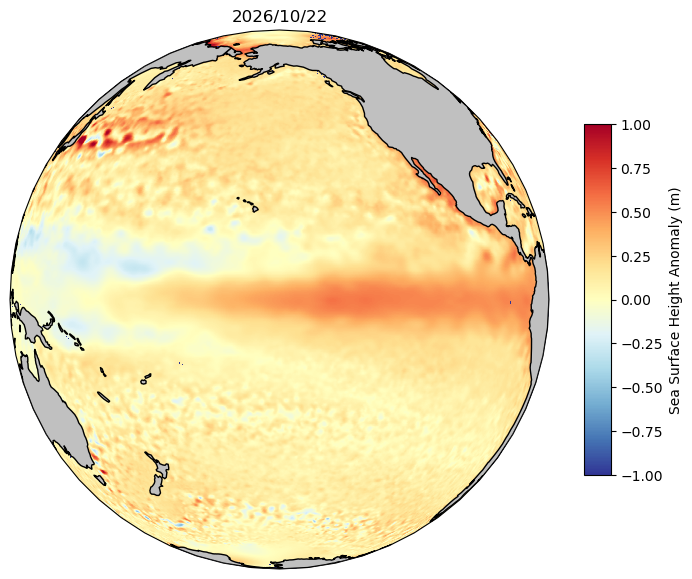

In [9]:
# define the input file path
input_file = os.path.join(data_folder,'SEALEVEL_GLO_PHY_L4_NRT_008_046',
                          'cmems_obs-sl_glo_phy-ssh_nrt_allsat-l4-duacs-0.125deg_P1D_202506',
                          '2026','10',
                          'nrt_global_allsat_phy_l4_20261022_20261025.nc')

# define the output file path
output_file = os.path.join(lab_directory,'ssha_panels','ssha_20261022.png')

# call the function to generate a plot
create_panel(input_file, output_file, save_as_image=False)

### Loop through the data panels
When you are happy with your plot, next we can loop through each file to create the panels for our movie

In [10]:
# define a path to the 2026 directory
directory_2026 = os.path.join(data_folder,'SEALEVEL_GLO_PHY_L4_NRT_008_046',
                          'cmems_obs-sl_glo_phy-ssh_nrt_allsat-l4-duacs-0.125deg_P1D_202506',
                          '2026')

# make a list of data files and sort them
file_list = []
for month in range(1,11): # this lab is in october so we just have 10 months
    for file_name in os.listdir(os.path.join(directory_2026, '{:02d}'.format(month))):
        if file_name[-3:]=='.nc' and file_name[0]!='.':
                file_list.append(os.path.join(directory_2026,
                                              '{:02d}'.format(month), file_name))
file_list.sort()

# loop through the file list and make a figure for each file
# define a counter for the file numbers
image_list = []
for file_path in file_list:
    
    # define the input file path
    input_file = file_path

    # define the output file path
    output_file = os.path.join(lab_directory,'ssha_panels',
                               'ssha_'+file_path.split('_')[-2]+'.png')
    image_list.append(output_file)
    
    # if the file isn't yet created, then make it
    if 'ssha_'+file_path.split('_')[-2]+'.png' not in os.listdir(os.path.join(lab_directory,'ssha_panels')):
        print('Making plot for '+'ssha_'+file_path.split('_')[-2]+'.png')
        create_panel(input_file, output_file)

## Part 3: Generating the Movie
Now that all of the panels are made, it's time to stitch them together into a movie.

In [11]:
# set the frames per second
fps=10

# use the ImageSequenceClip module to set up the clip
clip = moviepy.video.io.ImageSequenceClip.ImageSequenceClip(image_list, fps=fps)

# write the video to a file
clip.write_videofile(os.path.join(lab_directory,'SSH Anomalies 2026.mp4'))

Moviepy - Building video ../data/labs/lab09/SSH Anomalies 2026.mp4.
Moviepy - Writing video ../data/labs/lab09/SSH Anomalies 2026.mp4



Moviepy - Done !
Moviepy - video ready ../data/labs/lab09/SSH Anomalies 2026.mp4


In [12]:
from IPython.display import Video
Video('../images/labs/lab09/SSH Anomalies 2026.mp4', width=500, embed=True)

## Part 4: A Few Additional Movie Improvements

### Adding Elapsed Time to the Visualization

In the movie above, we could see the progression of the fields but it was difficult to see which dates these fields corresponded to because the date was rapidly changing in the header of the figure. An alternative method is to build an additional axis which keeps track of the time elapse over a given period. Here, we'll add one for 2026:

In [13]:
# create a function called create_panel that takes in the following arguments:
#       - input_file: a path to an input file (nc)
#       - output_file: a path to an output file (png)
def create_panel_with_timebar(input_file, output_file, save_as_image=True):

    # open the input_file and read the lon, lat, and data
    ds = nc4.Dataset(input_file)
    lon = np.copy(ds.variables['longitude'])
    lat = np.copy(ds.variables['latitude'])
    SLA = np.copy(ds.variables['sla'][:,:,:][0,:,:])
    ds.close()

    # make the figure
    fig = plt.figure(figsize=(7,6))

    gs = GridSpec(15, 10,
              left=0.05, right=0.95, bottom=0.05, top=0.95,
              hspace=0.01, wspace=0.05)

    # add an axis for the map
    ax1 = fig.add_subplot(gs[:-2,:], projection=ccrs.Orthographic(central_longitude=-150))
    C = ax1.pcolormesh(lon, lat, SLA,
                       transform=ccrs.PlateCarree(), vmin=-1, vmax=1, cmap='RdYlBu_r')
    cbar = plt.colorbar(C, shrink=0.65, aspect=20*0.65)
    cbar.set_label('Sea Surface Height Anomaly (m)')
    ax1.add_feature(cartopy.feature.LAND, zorder=99, edgecolor='black', facecolor='silver')
    
    # add an axis for the elapsed time bar
    ax2 = fig.add_subplot(gs[-1,:-1])
    year = int(input_file.split('_')[-2][:4])
    month = int(input_file.split('_')[-2][4:6])
    day = int(input_file.split('_')[-2][6:8])

    min_time = 0
    max_time = (date(2027,1,1)-date(2026,1,1)).total_seconds()
    width = (date(year,month,day)-date(2026,1,1)).total_seconds()
    rect = Rectangle((min_time, 0), width, 1, fc='silver', ec='k')
    ax2.add_patch(rect)
    ax2.set_xlim([min_time, max_time])
    ax2.set_ylim([0, 1])
    # for i in range(1,12):
    #     plt.plot([date.year+i/12,date.year+i/12],[0,1],'w-',linewidth=0.5)
    xticks = []
    for month in range(1,13):
        xticks.append((date(2026,month,1)-date(2026,1,1)).total_seconds())
    ax2.set_xticks(xticks)
    ax2.set_xticklabels(['J', 'F', 'M', 'A', 'M', 'J', 'J', 'A', 'S', 'O', 'N', 'D'])
    ax2.set_yticks([])
    ax2.set_xlabel('2026')

    if save_as_image:
        # save the figure to the output_file
        plt.savefig(output_file)#, bbox_inches='tight')
    
        # close the figure
        plt.close(fig)
    else:
        plt.show()

Let's see what the figure generated by this code looks like:

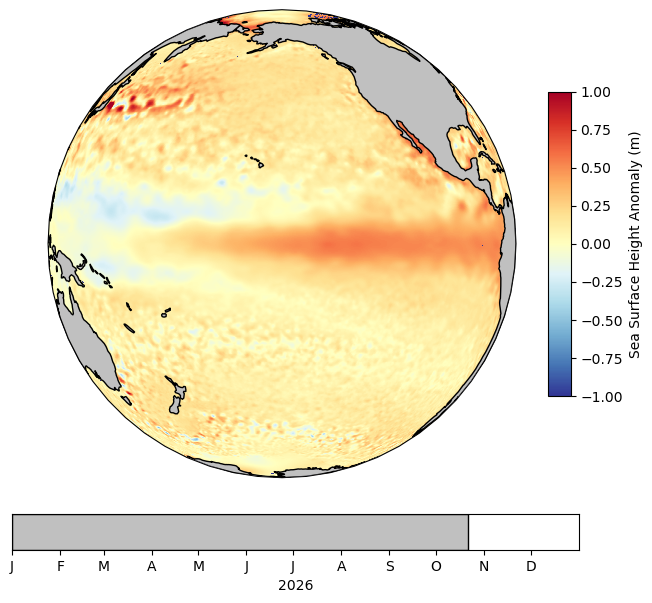

In [14]:
# define the input file path
input_file = os.path.join(data_folder,'SEALEVEL_GLO_PHY_L4_NRT_008_046',
                          'cmems_obs-sl_glo_phy-ssh_nrt_allsat-l4-duacs-0.125deg_P1D_202506',
                          '2026','10',
                          'nrt_global_allsat_phy_l4_20261022_20261025.nc')

# define the output file path
output_file = os.path.join(lab_directory,'ssha_panels','ssha_20261022.png')

# show the image with the time bar
create_panel_with_timebar(input_file, output_file, save_as_image=False)

#### &#129300; Try it for yourself
The above code shows how to make an axis for elapsed time in a given month. Adapt the code above to make an additional movie which shows the progression of time elapsed through the visualization.

### Adding a Time Series

The above code shows how to make an additional axis with the elapsed time. However, we could alternatively use our data to generate a time series for a given region of the domain.

#### &#129300; Try it for yourself
Modify the code above to plot a time series on the axis below the plot, rather than an elapsed time bar. Generate the time series first and then use a thick marker to identify the plotting date. The marker should move along the time series as the visualization progresses. 